In [9]:
import numpy as np
import matplotlib.pyplot as plt
import time
import os
from scipy.optimize import fsolve
from scipy.optimize import root_scalar
from scipy.optimize import approx_fprime
from scipy.optimize import root
from scipy.signal import argrelextrema
import numdifftools as nd
from matplotlib import colormaps
import warnings
plt.rcParams["figure.dpi"] = 120

# Prior to Jun 16

* compared pressure from my function and Alex's function, disagree
* was trying to see what could cause the difference, still reading Alex's code
* tryed to translate the code to python, still on going; rerwote partially in python in a customized package
* did plotting

**for next week**
* continue rewriting the code in a python package. ask questions if I have any (I think this is a way to help me learn RMF practically)
* put the plot to overleaf once we agreed that we have reached a sociologically suitable model

> write my own version of code that I understand each line
> at some point my code will diverge from Alex's anyways. 

some useful stuff from previous code

In [10]:
m_s = 100
m_B = 939
muK = np.linspace(-90,90,50)
muB = np.linspace(980, 1050,50)
muK_grid, muB_grid = np.meshgrid(muK, muB)

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

def PQM(muB, muK, B):
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB/3 - muK/2, m_s) - B
    
def PNM(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B)

def extract_contour_coords(X, Y, Z, level):
    fig, ax = plt.subplots()
    contour_obj = ax.contour(X, Y, Z, levels=[level])
    # Directly access the paths from the contour object
    paths = []
    for c in contour_obj.get_paths():
        paths.append(c.vertices)
    plt.close(fig)  # Close the plot if you only want data
    if not paths:
        raise RuntimeError(f"No contours found at level {level}")
    return paths[0][:, 0], paths[0][:, 1]

def aQstar_and_other_stuff(muB, muK, P_crit, Delta_P):  # the muB should be understood as muB_Qstar, and same for muK
    # calculate nB_Qstar, nK_Qstar using partial derivitives
    Qstar = np.array([muB, muK])
    grad_Qstar = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]

    # solve for muB_Q
    PQM_at_Q = lambda x: PQM(x, 0, B) - P_crit - Delta_P
    muB_Q = fsolve(PQM_at_Q, 1050)[0]  # 1050 is the starting point of numerical root finding

    # calculate nB_Q and nK_Q using partial derivitives
    Q = np.array([muB_Q, 0])  # the point Q
    grad_Q = approx_fprime(Q, PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]

    return (nK_Qstar - nK_Q)/nB_Q , nB_Q, muB_Q

### here uses the package I made according to Alex's code

In [11]:
from RMFsolver import Solver
import RMFsolver.RMFparameter as para

def PNM_qmc(mu_B, Tem):
    sol = Solver.RMFsolve_mu(
    mub=mu_B,                  # baryon chemical potential in MeV
    Trmf=Tem,                 # temperature in MeV
    para=para.paraQMCRMF3,    # model parameter set
    sigma_init=30,            # initial guess for sigma
    w0_init=20,               # initial guess for w0
    r03_init=-3,              # initial guess for r03
    mu_e_init=50.0,           # initial guess for mu_e
    verb=False                # verbose output
    )
    return (Solver.pressure_RMF(sol)).item()

testing

In [12]:
print(f"{PNM_qmc(1020, Tem=100):.6e}")

6.753212e+08


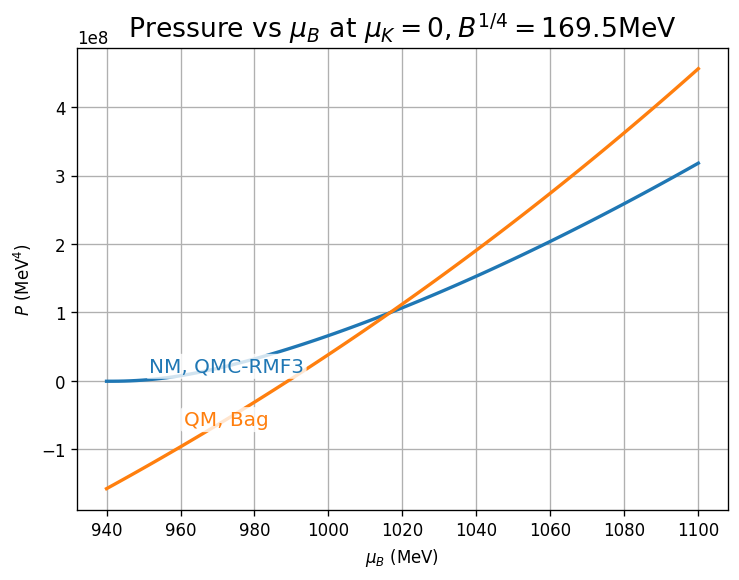

In [13]:
muB = np.linspace(940, 1100, 100)  # 43

'''
P_nonint = []
muB_nonint = [] 
for k_F in kF:
    tmp1, tmp2 = PNM(k_F)
    P_nonint.append(tmp1)
    muB_nonint.append(tmp2)
'''

B_one_forth = 169.5
B = B_one_forth**4

P_qmc = []
for mu_b in muB:
    P_qmc.append(PNM_qmc(mu_b, 0))
P_QM = PQM(muB, 0, B)

plt.figure(figsize=(7, 5))

#plt.plot(muB_W, [PNM_old(x) for x in muB_W], 'b')
plt.plot(muB, P_qmc, lw=2, color='tab:blue')
#plt.plot(np.linspace(910, 1010, 100), np.zeros(100), 'k')
plt.plot(muB, P_QM, lw=2, color='tab:orange')
plt.xlabel(r'$\mu_B$ (MeV)')
plt.ylabel(r'$P$ (MeV$^4$)')
#plt.text(980, 5e+6, "Non-interacting")
#plt.text(965, 8e+7, "Walecka")

boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB[20], P_qmc[20], "NM, QMC-RMF3", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB[20],  PQM(muB[20], 0, B),  "QM, Bag", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)

plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B^{1/4}=$'+str(B_one_forth)+'MeV', fontsize=16)
plt.grid(True)

In [14]:
type(PQM(1000,0,169.5**4).item()), type(PNM_qmc(1000,0)), type(P_diff(1000))

(float, float, float)

In [15]:
out = Solver.RMFsolve_mu(
    mub=1000,                  # baryon chemical potential in MeV
    Trmf=0,                 # temperature in MeV
    para=para.paraQMCRMF3,    # model parameter set
    sigma_init=30,            # initial guess for sigma
    w0_init=20,               # initial guess for w0
    r03_init=-3,              # initial guess for r03
    mu_e_init=50.0,           # initial guess for mu_e
    verb=False                # verbose output
    )
type(out)

list

In [16]:
P_diff = lambda x: PQM(x, 0, 169.5**4).item() - PNM_qmc(x, 0)
fsolve(P_diff, 1050)

array([1016.62366396])

In [17]:
muK = np.linspace(-90,90,100)
muK_grid, muB_grid = np.meshgrid(muK, muB)
P_QM = PQM(muB_grid, muK_grid, B)
P_NM = np.ones([len(muB), len(muK)])
for i in range(len(muB)):
    for j in range(len(muK)):
        P_NM[i,j] = PNM_qmc(muB[i], 0)
        print(i,j)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
0 25
0 26
0 27
0 28
0 29
0 30
0 31
0 32
0 33
0 34
0 35
0 36
0 37
0 38
0 39
0 40
0 41
0 42
0 43
0 44
0 45
0 46
0 47
0 48
0 49
0 50
0 51
0 52
0 53
0 54
0 55
0 56
0 57
0 58
0 59
0 60
0 61
0 62
0 63
0 64
0 65
0 66
0 67
0 68
0 69
0 70
0 71
0 72
0 73
0 74
0 75
0 76
0 77
0 78
0 79
0 80
0 81
0 82
0 83
0 84
0 85
0 86
0 87
0 88
0 89
0 90
0 91
0 92
0 93
0 94
0 95
0 96
0 97
0 98
0 99
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17
1 18
1 19
1 20
1 21
1 22
1 23
1 24
1 25
1 26
1 27
1 28
1 29
1 30
1 31
1 32
1 33
1 34
1 35
1 36
1 37
1 38
1 39
1 40
1 41
1 42
1 43
1 44
1 45
1 46
1 47
1 48
1 49
1 50
1 51
1 52
1 53
1 54
1 55
1 56
1 57
1 58
1 59
1 60
1 61
1 62
1 63
1 64
1 65
1 66
1 67
1 68
1 69
1 70
1 71
1 72
1 73
1 74
1 75
1 76
1 77
1 78
1 79
1 80
1 81
1 82
1 83
1 84
1 85
1 86
1 87
1 88
1 89
1 90
1 91
1 92
1 93
1 94
1 95
1 96
1 97
1 98
1 99
2 0
2 1
2 2
2 3
2 4


1016.759345800413


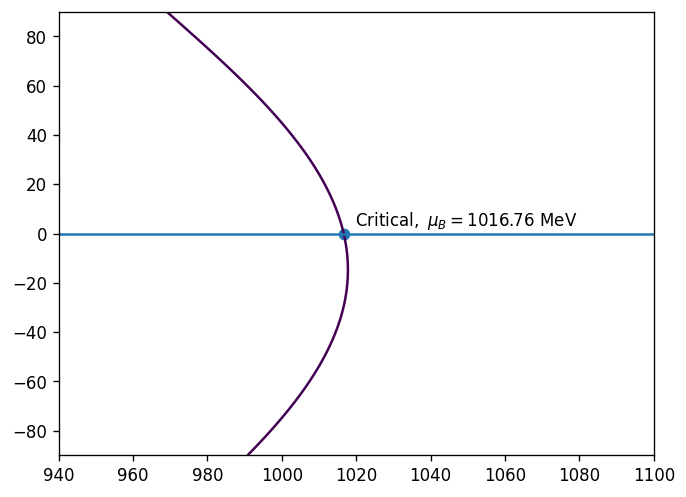

In [19]:
muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM - P_NM, level = 0)
min_ind = np.argmin(np.abs(muK_contour_coor))
muB_crit = muB_contour_coor[min_ind]
print(muB_crit)
P_crit = PQM(muB_crit, 0, B)

#PNM_minus_PShift = lambda x: PNM_qmc1(x)[0] - P_crit
#muB_crit = PNM_qmc1(fsolve(PNM_minus_PShift, 1050))[1]

plt.scatter(muB_crit,0) 
plt.text(muB_crit+3, 3, rf"$\mathrm{{Critical}},\ \mu_B = {muB_crit:.2f}\ \mathrm{{MeV}}$")

# rf"$N,\ \mu_B = {muB_N.item():.2f}\ \mathrm{{MeV}}$"
#muB_crit
#muB_crit = 978.8

contours = plt.contour(muB_grid, muK_grid, P_QM - P_NM, levels=[0])
#contours = plt.contour(muB_grid, muK_grid, P_QM, levels=[0])
plt.plot(muB, np.zeros(len(muB)))

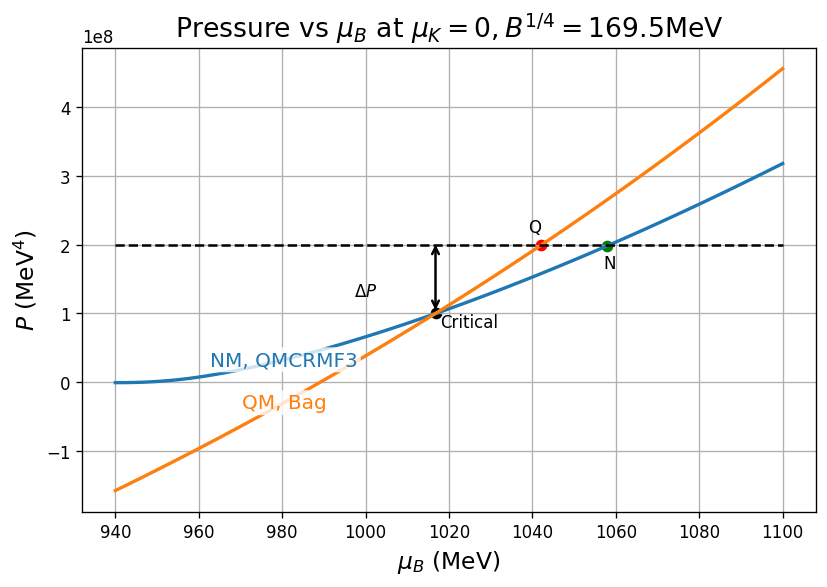

In [20]:
# Plot
Delta_P = 1e+8
plt.figure(figsize=(7, 5))
plt.plot(muB, P_qmc, lw=2, color='tab:blue')
plt.plot(muB, PQM(muB, 0, B), lw=2, color='tab:orange')

# Tight background box
boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB[25], P_qmc[25], "NM, QMCRMF3", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB[25],  PQM(muB[25], 0, B),  "QM, Bag", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)
plt.scatter(muB_crit, P_crit, c='k') # 3.6e+7
plt.text(muB_crit+1, 0.8*P_crit, r"Critical")
plt.plot(muB, (P_crit + Delta_P)*np.ones(len(muB)), 'k--')
plt.scatter(1042, PQM(1042, 0, B), c='r')
plt.text(1039, PQM(1042,0,B)*1.1, r"Q")
plt.scatter(1058, PNM_qmc(1058,0), c='g')
plt.text(1057, 0.85*PNM_qmc(1057,0), r"N")

plt.annotate(
    '', 
    xy=(muB_crit, P_crit), 
    xytext=(muB_crit, P_crit+Delta_P*1.05
           ),
    arrowprops=dict(arrowstyle='<->', color='black', lw=1.5),
)
# Optional label for the arrow
plt.text(1002.1-5, (P_crit + Delta_P)/1.5, r'$\Delta P$', va='center')


plt.xlabel(r'$\mu_B$ (MeV)', fontsize=14)
plt.ylabel(r'$P$ (MeV$^4$)', fontsize=14)
plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B^{1/4}=$'+str(B_one_forth)+'MeV', fontsize=16)
plt.grid(True)
plt.tight_layout()


# Define the path to the Downloads folder
downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "QMC-RMF3-1.pdf"), dpi=300)

In [21]:
PNM_minus_PShift = lambda x: PNM_qmc(x[0],0) - P_crit - Delta_P
muB_N = fsolve(PNM_minus_PShift, [1050])[0]
muB_N

np.float64(1058.5473164678656)

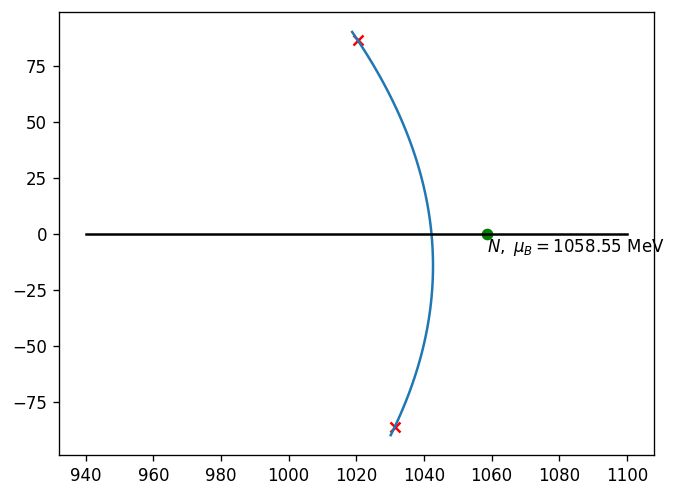

In [22]:
# plot contour
muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
plt.plot(muB_contour_coor, muK_contour_coor)
plt.plot(muB, np.zeros(len(muB)), 'k')

# plotting N
PNM_minus_PShift = lambda x: PNM_qmc(x[0],0) - P_crit - Delta_P
muB_N = fsolve(PNM_minus_PShift, [1050])[0]
plt.scatter(muB_N,0, c='g')
plt.text(muB_N, -8, rf"$N,\ \mu_B = {muB_N.item():.2f}\ \mathrm{{MeV}}$")

# plotting cross
mu_average = []
epsilon = np.sqrt(np.finfo(float).eps)
for i in range(len(muB_contour_coor)):
    muB_Qstar = muB_contour_coor[i]
    muK_Qstar = muK_contour_coor[i]
    Qstar = np.array([muB_Qstar, muK_Qstar])
    grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
    nB_Qstar = grad[0]
    nK_Qstar = grad[1]
    mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
difference = np.abs(np.array(mu_average) - muB_N)
minima_ind = argrelextrema(difference, np.less)[0]

plt.scatter(muB_contour_coor[minima_ind[0]],muK_contour_coor[minima_ind[0]], marker='x', c='r')
plt.scatter(muB_contour_coor[minima_ind[1]],muK_contour_coor[minima_ind[1]], marker='x', c='r')

#plt.scatter(np.array([i for i in range(len(mu_average))]), mu_average, s=0.1)
#plt.plot(np.array([i for i in range(len(mu_average))]), muB_N*np.ones(len(mu_average)))

In [24]:
muB_contour_coor[minima_ind[1]] ,muK_contour_coor[minima_ind[1]]

(np.float64(1020.4106790510967), np.float64(86.36363636363635))

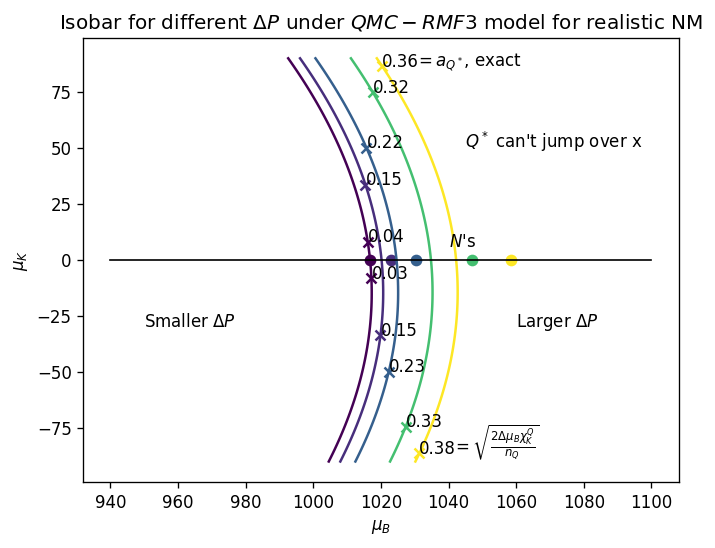

In [13]:
from scipy.signal import argrelextrema
from scipy.optimize import fsolve
import numdifftools as nd
from matplotlib import colormaps
cmap = colormaps['viridis']

Delta = np.array([1e+5, 1.3e+7, 3e+7, 7e+7, 1e+8]) #P_crit * np.array([0.1, 0.2, 0.3, 0.4, 0.5])

for Delta_P in Delta:
    muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, level = P_crit + Delta_P)
    mu_average = []
    for i in range(len(muB_contour_coor)):
        muB_Qstar = muB_contour_coor[i]
        muK_Qstar = muK_contour_coor[i]
        Qstar = np.array([muB_Qstar, muK_Qstar])
        grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu at Qstar!!!
        nB_Qstar = grad[0]
        nK_Qstar = grad[1]
        mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)
    PNM_minus_PShift = lambda x: PNM_qmc(x[0],0) - P_crit - Delta_P
    muB_N = fsolve(PNM_minus_PShift, [1050])[0]
    difference = np.abs(np.array(mu_average) - muB_N)
    minima_ind = argrelextrema(difference, np.less)[0]  # this is where the cross is (the index) along the contour line

    muB_Qstar_down = muB_contour_coor[minima_ind[0]]
    muK_Qstar_down = muK_contour_coor[minima_ind[0]]
    muB_Qstar_up = muB_contour_coor[minima_ind[1]]
    muK_Qstar_up = muK_contour_coor[minima_ind[1]]
    
    a_Q_star, nBQ, muBQ = aQstar_and_other_stuff(muB_Qstar_up, muK_Qstar_up, P_crit, Delta_P) # should only use upper value

    # the following calculates a_Q_star_max using the analytical approximation from taylor expansion
    PQM_at_Q = lambda x: PQM(muBQ, x, B) - P_crit - Delta_P
    d2f = nd.Derivative(PQM_at_Q, n=2)
    chiK_Q = d2f(0)
    a_Q_star_max = np.sqrt((2 * (muB_N - muBQ) * chiK_Q) / nBQ)

    # plotting the crosses and the corresponding exact aQstar (on upper branch) and analytical aQstar (on down branch)
    col = cmap(Delta_P/Delta[-1])
    plt.plot(muB_contour_coor, muK_contour_coor, color = col)
    plt.scatter(muB_Qstar_down,muK_Qstar_down, marker='x', color=col)
    plt.scatter(muB_Qstar_up,muK_Qstar_up, marker='x', color=col)
    plt.text(muB_Qstar_up,muK_Qstar_up, f"{a_Q_star:.2f}")
    plt.text(muB_Qstar_down,muK_Qstar_down, f"{a_Q_star_max:.2f}")
    plt.scatter(muB_N, 0, color=col)
    

plt.text(1060, -30, r"Larger $\Delta P$")
plt.text(950, -30, r"Smaller $\Delta P$")
plt.text(1045, 50, r"$Q^*$ can't jump over x")
plt.text(1030, 86.3, r"$=a_{Q^*}$, exact")
plt.text(1041, -86, r"$=\sqrt{\frac{2\Delta\mu_B\chi_K^Q}{n_Q}}$")
plt.text(1040, 6, r"$N$'s")
plt.plot(muB, np.zeros(len(muB)), 'k', lw=1)
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.title(r"Isobar for different $\Delta P$ under $QMC-RMF3$ model for realistic NM") 

# Define the path to the Downloads folder
downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "QMC-RMF3-2.pdf"), dpi=300)

# Prior to Jun 25

* testing my python package
* understanding Alex's code
* reading papers, learning stuff

Question:
* since direct integral and indirect $s = \frac{P + \epsilon - \mu n}{T}$
* when will $\phi$ meson become relavant? It's made up by $\overline{s}s$, so it only become relavant when there's hyperons? 

# Prior to Jul 8

have the velocity function up and running, there's something I noticed:
$$
a_N = \frac{n_N}{n_Q} = \frac{\partial P_{NM}/\partial \mu_B|_N}{\partial P_{QM}/\partial \mu_B|_Q}
$$
* sometimes $a_N < a_{Q^*}$, making the velocity purely immaginary... Due to the relation above, if the slope for QM is much larger than that for NM, this happens. The paper claimed that $a_N\gg a_{Q^*}$, so there should be an assumption for this
> this might be served as annother constraint for $a_{Q^*}$: requiring it to be less than $a_N$. This constraint is $n_{B}^N > n_{K}^{Q^*}$. The physical meaning is we want the direction of flavor diffusion is from SQM to NM. 
* to calculate $a_{Q^*}$ in the code, there's two approaches. one is using the approximation method, the other is to numerically calculate the accurate one. these two methods agrees pretty well $\sim 10\%$, and using the approximation method is faster and more robust.
* $\Delta P$ is still an input of the function. I think the bag constant for SQM cannot determine this from a straight forward way, it needs information about the pressure distribution from simulations:
> relative velocity between phase boundary and the surface when $P = P_{crit}$ is $v$. When $v$ is large, the two surfaces are getting further away, incleasing $\Delta P$, which makes maximum $a_{Q^*}$ increase, and hence increasing $v_{N\to Q}$, which decreases $v$. So there should be some sort of balance.
* I further checked how sensitive is $v_{N\to Q}$ is when changing $\Delta P$: when $\Delta P$ increases by one order of magnitude, $v_{N\to Q}$ becomes about 5 times larger. 

In [6]:
from RMFsolver.phase_velocity import vNtoQ
import RMFsolver.RMFparameter as para
import time

start = time.time()
ve = vNtoQ(
    T = 10,                   # temperature in MeV
    B_SQM = 150,              # Bag constant for quark matter bag model, in MeV
    DelP = 1e+7,              # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 100,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM"           # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
)
end = time.time()

ve

aQstar = 0.7514772297229653 > aN = 0.3081655738723797


In [26]:
print("NM to QM phase boundary moving velocity = "+str(ve)+" (m/s)")
print("code takes "+str(end - start)+" seconds to run")

NM to QM phase boundary moving velocity = 45.895182424232516 (m/s)
code takes 5.536875009536743 seconds to run


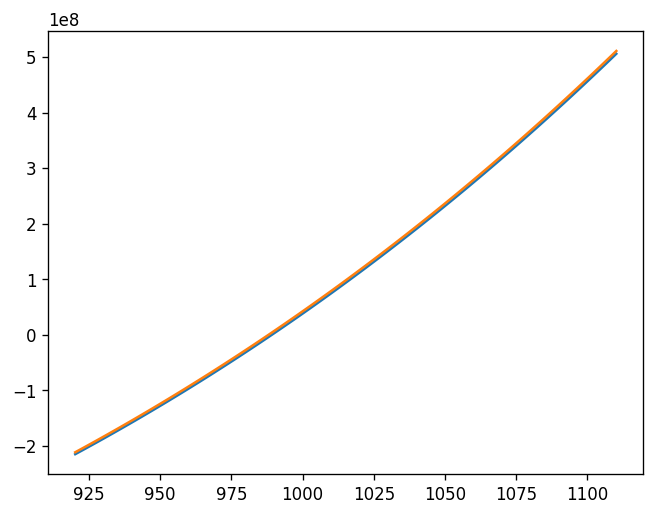

In [21]:
import RMFsolver.phase_velocity as ps

muB_crit = 1010.1584924141733
B_SQM = 169.5
T = 5
m_s = 100

mubb = np.linspace(muB_crit-90, muB_crit+100, 100)
P_QM1 = np.array([PQM(x, 0, B_SQM**4) for x in mubb])
P_QM2 = np.array([ps.PQM(x, 0, B_SQM, T, m_s) for x in mubb])

plt.plot(mubb, P_QM1)
plt.plot(mubb, P_QM2)

# Prior to Jul 11

* understand how $v_{N\to Q}$ depends on different variables
* do contour plots and so on

questions:
* using $a_{Q^*}$ maximum, which might not indicate where the true $Q^*$ is. Using larger $a_{Q^*}$ will exaggerate the velocity.
* average quark chemical potential also enters the formula for $v_{N\to Q}$. there're several values; should we plug in $\mu_B^{Q^*}/3$, or $\mu_B^N/3$
* I'm not sure if the formula works for $T=0$ since it'll just diverge if $T=0$

### find out a window of safe parameter space: $T-B_{SQM}$ space

In [7]:
from RMFsolver.phase_velocity import vNtoQ
import RMFsolver.RMFparameter as para
import time

start = time.time()
ve = vNtoQ(
    T = 1,                   # temperature in MeV
    B_SQM = 195,              # Bag constant for quark matter bag model, in MeV
    DelP = 1e+7,              # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 100,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM",          # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "numerical"
)
end = time.time()

ve

np.float64(36.040593416818936)

In [8]:
import numpy as np
import matplotlib.pyplot as plt

N = 25
meth = "numerical"

TT = np.linspace(1, 25, N)    # y-axis (rows)
BB = np.linspace(167, 195, N) # x-axis (columns)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ(
            T = TT[i],
            B_SQM = BB[j],
            DelP = 1e+7,
            m_s = 100,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j)

np.save("B_T_N="+str(N)+"_"+meth+".npy", V)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17
1 18
1 19
1 20
1 21
1 22
1 23
1 24


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


2 0


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


2 1


...

5 20
5 21
5 22


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


5 23


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:46: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


5 24
6 0
6 1
6 2
6 3
6 4
6 5
6 6
6 7
6 8
6 9
6 10
6 11
6 12
6 13
6 14
6 15
6 16
6 17
6 18
6 19
6 20
6 21
6 22
6 23
6 24
7 0
7 1
7 2
7 3
7 4
7 5
7 6
7 7
7 8
7 9
7 10
7 11
7 12
7 13
7 14
7 15
7 16
7 17
7 18
7 19
7 20
7 21
7 22
7 23
7 24
8 0
8 1
8 2
8 3
8 4
8 5
8 6
8 7
8 8
8 9
8 10
8 11
8 12
8 13
8 14
8 15
8 16
8 17
8 18
8 19
8 20
8 21
8 22
8 23
8 24
9 0
9 1
9 2
9 3
9 4
9 5
9 6
9 7
9 8
9 9
9 10
9 11
9 12
9 13
9 14
9 15
9 16
9 17
9 18
9 19
9 20
9 21
9 22
9 23
9 24
10 0
10 1
10 2
10 3
10 4
10 5
10 6
10 7
10 8
10 9
10 10
10 11
10 12
10 13
10 14
10 15
10 16
10 17
10 18
10 19
10 20
10 21
10 22
10 23
10 24
11 0
11 1
11 2
11 3
11 4
11 5
11 6
11 7
11 8
11 9
11 10
11 11
11 12
11 13
11 14
11 15
11 16
11 17
11 18
11 19
11 20
11 21
11 22
11 23
11 24
12 0
12 1
12 2
12 3
12 4
12 5
12 6
12 7
12 8
12 9
12 10
12 11
12 12
12 13
12 14
12 15
12 16
12 17
12 18
12 19
12 20
12 21
12 22
12 23
12 24
13 0
13 1
13 2
13 3
13 4
13 5
13 6
13 7
13 8
13 9
13 10
13 11
13 12
13 13
13 14
13 15
13 16
13 17
13 18
13 19
13 20

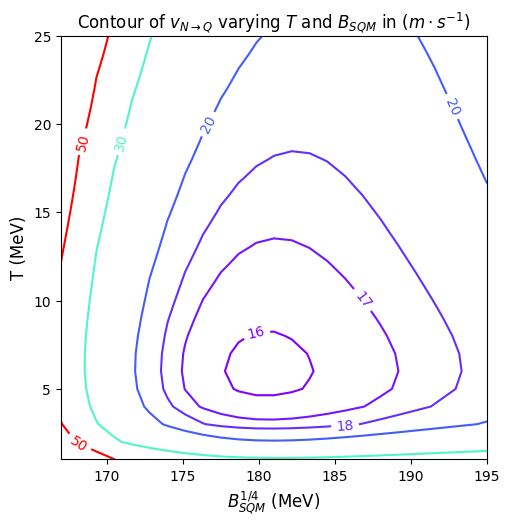

In [9]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
#B_grid, T_grid = np.meshgrid(BB, TT)  # note BB first for x, TT for 

TT = np.linspace(1, 25, N)    # y-axis (rows)
BB = np.linspace(167, 195, N) # x-axis (columns)
V_tmp = np.load("B_T_N="+str(N)+"_"+meth+".npy")
B_grid_tmp, T_grid_tmp = np.meshgrid(BB, TT)

contours = plt.contour(B_grid_tmp, T_grid_tmp, V_tmp, levels = np.array([16, 17, 18, 20, 30, 50]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}$ varying $T$ and $B_{SQM}$ in $(m\cdot s^{-1})$")
plt.xlabel(r"$B_{SQM}^{1/4}$ (MeV)", fontsize=12)
plt.ylabel("T (MeV)", fontsize=12)

plt.savefig("B_T_N="+str(N)+"_"+meth+".pdf", dpi=300)  # Increase DPI as needed

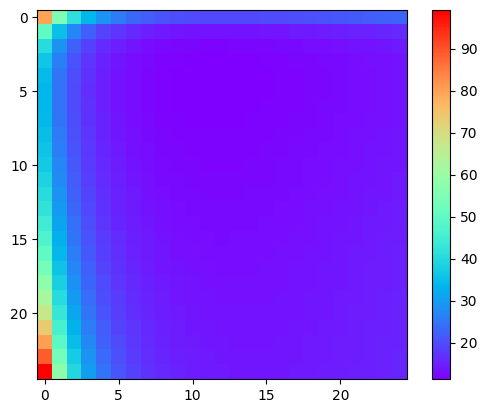

In [13]:
Vac = np.load("B_T_N=25accurate.npy")
Van = np.load("B_T_N=25analytical.npy")
plt.imshow(Van, cmap='rainbow')
plt.colorbar()  # optional: shows the color scale
plt.show()

In [24]:
V.min(), V.max(), V[0,0]

(np.float64(102.74618318717133),
 np.float64(1676.0921585496137),
 np.float64(856.108168996385))

In [10]:
V[-1,0], T_grid[-1,0], B_grid[-1,0]

(np.float64(0.0), np.float64(23.0), np.float64(165.0))

In [18]:
360*3

1080

### find out a window of safe parameter space: $T-\Delta P$ space

In [54]:
from RMFsolver.phase_velocity import vNtoQ
import RMFsolver.RMFparameter as para
import time

start = time.time()
ve = vNtoQ(
    T = 23,                    # temperature in MeV
    B_SQM = 180,              # Bag constant for quark matter bag model, in MeV
    DelP = 1e+8,              # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 100,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM",          # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "analytical"
)
end = time.time()

ve

np.float64(54.319694906051055)

In [35]:
import numpy as np
import matplotlib.pyplot as plt

N = 25
meth = "analytical"

TT = np.linspace(1, 30, N)
DD = np.linspace(1e+6, 1e+8, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ(
            T = TT[i],
            B_SQM = 180,
            DelP = DD[j],
            m_s = 100,
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j)

np.save("DelP_T_N="+str(N)+"_"+meth+".npy", V)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17
1 18
1 19
1 20
1 21
1 22
1 23
1 24
2 0
2 1
2 2
2 3
2 4
2 5
2 6
2 7
2 8
2 9
2 10
2 11
2 12
2 13
2 14
2 15
2 16
2 17
2 18
2 19
2 20
2 21
2 22
2 23
2 24
3 0
3 1
3 2
3 3
3 4
3 5
3 6
3 7
3 8
3 9
3 10
3 11
3 12
3 13
3 14
3 15
3 16
3 17
3 18
3 19
3 20
3 21
3 22
3 23
3 24
4 0
4 1
4 2
4 3
4 4
4 5
4 6
4 7
4 8
4 9
4 10
4 11
4 12
4 13
4 14
4 15
4 16
4 17
4 18
4 19
4 20
4 21
4 22
4 23
4 24
5 0
5 1
5 2
5 3
5 4
5 5
5 6
5 7
5 8
5 9
5 10
5 11
5 12
5 13
5 14
5 15
5 16
5 17
5 18
5 19
5 20
5 21
5 22
5 23
5 24
6 0
6 1
6 2
6 3
6 4
6 5
6 6
6 7
6 8
6 9
6 10
6 11
6 12
6 13
6 14
6 15
6 16
6 17
6 18
6 19
6 20
6 21
6 22
6 23
6 24
7 0
7 1
7 2
7 3
7 4
7 5
7 6
7 7
7 8
7 9
7 10
7 11
7 12
7 13
7 14
7 15
7 16
7 17
7 18
7 19
7 20
7 21
7 22
7 23
7 24
8 0
8 1
8 2
8 3
8 4
8 5
8 6
8 7
8 8
8 9
8 10
8 11
8 12
8 13
8 14
8 15
8 16
8 17


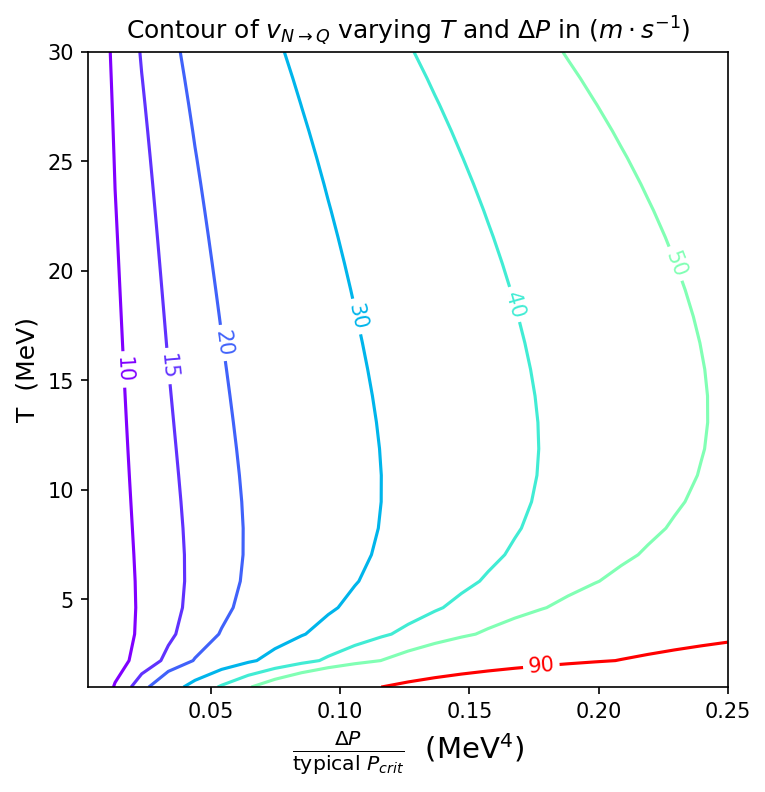

In [97]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
T_grid, D_grid = np.meshgrid(TT, DD)  # note BB first for x, TT for 

V_old = np.load("DelP_T_N=25analytical.npy")
D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(D_grid_old, T_grid_old, V_old, levels = np.array([10, 15, 20, 30, 40, 50, 90]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}$ varying $T$ and $\Delta P$ in $(m\cdot s^{-1})$")
plt.xlabel(r"$\frac{\Delta P}{\text{typical }P_{crit}}$  (MeV$^4$)", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

plt.savefig("DelP_T_N=25analytical.pdf", dpi=300)  # Increase DPI as needed

### Changing $T-m_s$

In [62]:
from RMFsolver.phase_velocity import vNtoQ
import RMFsolver.RMFparameter as para
import time

start = time.time()
ve = vNtoQ(
    T = 1,                    # temperature in MeV
    B_SQM = 180,              # Bag constant for quark matter bag model, in MeV
    DelP = 1e+7,              # measures how far from equilibrium; this can't be determined from bag constant
    m_s = 500,                # strange quark mass
    param = para.paraQMCRMF3, # RMF model for nuclear matter
    NM_type = "PNM",          # nuclear matter type: pure neutron NM. other options: Beta_eq, SYM
    method = "analytical"
)
end = time.time()

ve

np.float64(13.443678383107258)

In [63]:
import numpy as np
import matplotlib.pyplot as plt

N = 25
meth = "analytical"

TT = np.linspace(1, 23, N)
MM = np.linspace(10, 500, N)

V = np.zeros([N, N])

for i in range(N):  # loop over T (rows)
    for j in range(N):  # loop over B (columns)
        V[i, j] = vNtoQ(
            T = TT[i],
            B_SQM = 180,
            DelP = 1e+7,
            m_s = MM[j],
            param = para.paraQMCRMF3,
            NM_type = "PNM",
            method = meth
        )
        print(i, j)

np.save("MS_T_N="+str(N)+meth+".npy", V)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
0 20
0 21
0 22
0 23
0 24
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17
1 18
1 19
1 20


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:45: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)


1 21
1 22
1 23
1 24
2 0
2 1
2 2
2 3
2 4
2 5
2 6
2 7
2 8
2 9
2 10
2 11
2 12
2 13
2 14
2 15
2 16
2 17
2 18


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:45: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:45: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and

2 19


...

7 23


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:45: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:45: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and

7 24
8 0
8 1
8 2
8 3
8 4
8 5
8 6
8 7
8 8
8 9
8 10
8 11
8 12
8 13
8 14
8 15
8 16
8 17
8 18
8 19
8 20
8 21
8 22
8 23


/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:45: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral, _ = quad(integrand, 0, upB, epsabs=1e-10, epsrel=1e-8)
/Users/janshao/NSM_related/RMFsolver/phase_velocity.py:45: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and

8 24
9 0
9 1
9 2
9 3
9 4
9 5
9 6
9 7
9 8
9 9
9 10
9 11
9 12
9 13
9 14
9 15
9 16
9 17
9 18
9 19
9 20
9 21
9 22
9 23
9 24
10 0
10 1
10 2
10 3
10 4
10 5
10 6
10 7
10 8
10 9
10 10
10 11
10 12
10 13
10 14
10 15
10 16
10 17
10 18
10 19
10 20
10 21
10 22
10 23
10 24
11 0
11 1
11 2
11 3
11 4
11 5
11 6
11 7
11 8
11 9
11 10
11 11
11 12
11 13
11 14
11 15
11 16
11 17
11 18
11 19
11 20
11 21
11 22
11 23
11 24
12 0
12 1
12 2
12 3
12 4
12 5
12 6
12 7
12 8
12 9
12 10
12 11
12 12
12 13
12 14
12 15
12 16
12 17
12 18
12 19
12 20
12 21
12 22
12 23
12 24
13 0
13 1
13 2
13 3
13 4
13 5
13 6
13 7
13 8
13 9
13 10
13 11
13 12
13 13
13 14
13 15
13 16
13 17
13 18
13 19
13 20
13 21
13 22
13 23
13 24
14 0
14 1
14 2
14 3
14 4
14 5
14 6
14 7
14 8
14 9
14 10
14 11
14 12
14 13
14 14
14 15
14 16
14 17
14 18
14 19
14 20
14 21
14 22
14 23
14 24
15 0
15 1
15 2
15 3
15 4
15 5
15 6
15 7
15 8
15 9
15 10
15 11
15 12
15 13
15 14
15 15
15 16
15 17
15 18
15 19
15 20
15 21
15 22
15 23
15 24
16 0
16 1
16 2
16 3
16 4
16 5
16 6
16 7


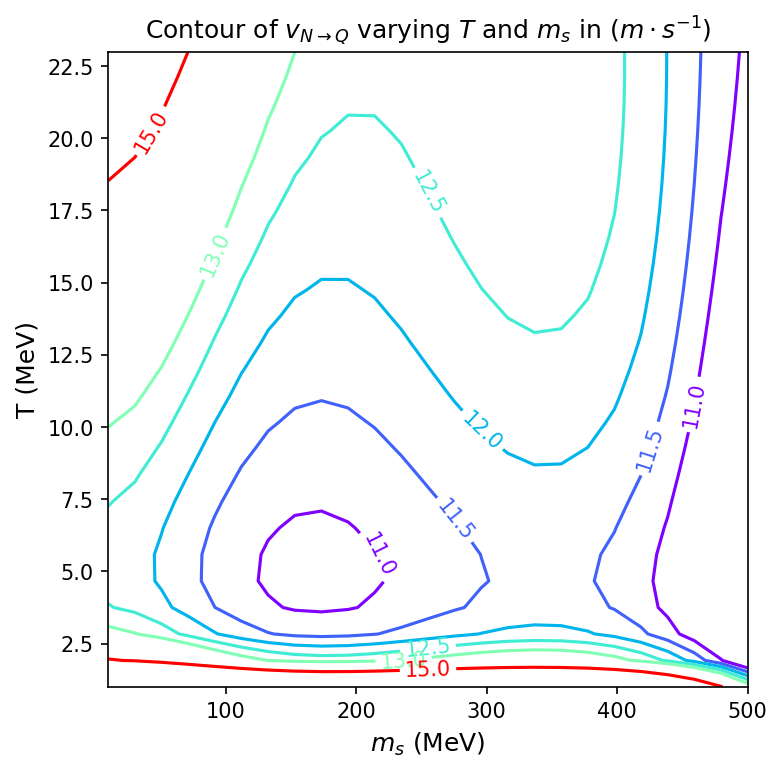

In [96]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
T_grid, M_grid = np.meshgrid(TT, MM)  # note BB first for x, TT for 

#V_old = np.load("B_T.npy")
#B_grid_old, T_grid_old = np.meshgrid(np.linspace(165, 195, 20), np.linspace(0.1, 23, 20))

contours = plt.contour(M_grid, T_grid, V.T, levels = np.array([11, 11.5, 12, 12.5, 13, 15, ]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $v_{N\to Q}$ varying $T$ and $m_s$ in $(m\cdot s^{-1})$")
plt.xlabel(r"$m_s$ (MeV)", fontsize=12)
plt.ylabel("T (MeV)", fontsize=12)

plt.savefig("MS_T_N=25analytical.pdf", dpi=300)  # Increase DPI as needed

In [65]:
V.min(), V.max()

(np.float64(9.153051391067208), np.float64(21.997448730620956))

* use more understandable $\Delta P/P_{cr}$ on x axis
* $m_s$, $B$ as external parameters, just tune a few value then under each value do the $T-\Delta P$ contour plots
* change $T$, plot $P_{NM}$, $P_{QM}$, $a_{Q^*}$, $a_N$ for $\mu_K = 0$

# Garbage code